## Part 1 – Import Libraries
`RANDOM_STATE` is fixed so that the split and the tree results are reproducible.

In [4]:
%pip install scikit-learn


[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42

## Part 2 – Load the Dataset

In [6]:
df = pd.read_csv("DSA2050_Week6_Sales_Data.csv")
display(df.head())
print("Shape:", df.shape)
print()
df.info()

,AdvertisingSpend_KES,StoreVisits,DiscountPercent,Region,CustomerSegment,ProductCategory,Sales_KES
0,10801,326,17,Nairobi,SME,Electronics,152376
1,55307,162,23,Nairobi,Retail,Home,119137
2,47547,553,22,Mombasa,Corporate,Office,219441
3,33527,785,12,Nairobi,SME,Electronics,234210
4,33145,830,20,Nairobi,Retail,Home,204277


Shape: (320, 7)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 320 entries, 0 to 319
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   AdvertisingSpend_KES  320 non-null    int64 
 1   StoreVisits           320 non-null    int64 
 2   DiscountPercent       320 non-null    int64 
 3   Region                320 non-null    object
 4   CustomerSegment       320 non-null    object
 5   ProductCategory       320 non-null    object
 6   Sales_KES             320 non-null    int64 
dtypes: int64(4), object(3)
memory usage: 17.6+ KB


**Student check**
- **Size:** 320 rows × 7 columns.
- **Numeric variables:** `AdvertisingSpend_KES`, `StoreVisits`, `DiscountPercent`, and the target `Sales_KES`.
- **Categorical variables:** `Region` (4 levels), `CustomerSegment` (3 levels), `ProductCategory` (4 levels).
- **One row** represents one business record (an observation of a region / customer segment / product category combination with its advertising spend, store visits, discount level and resulting sales).
- **Target:** `Sales_KES`, a continuous value, so this is a regression problem.

## Part 3 – Basic Data Audit

Missing values:


AdvertisingSpend_KES    0
StoreVisits             0
DiscountPercent         0
Region                  0
CustomerSegment         0
ProductCategory         0
Sales_KES               0
dtype: int64

Duplicate rows: 0


,AdvertisingSpend_KES,StoreVisits,DiscountPercent,Region,CustomerSegment,ProductCategory,Sales_KES
count,320.000000,320.000000,320.000000,320,320,320,320.000000
unique,NaN,NaN,NaN,4,3,4,NaN
top,NaN,NaN,NaN,Nairobi,Retail,Electronics,NaN
freq,NaN,NaN,NaN,139,157,95,NaN
mean,37421.784375,465.440625,12.806250,NaN,NaN,NaN,169252.446875
std,17745.832695,231.651173,7.717583,NaN,NaN,NaN,51968.081691
min,5478.000000,84.000000,0.000000,NaN,NaN,NaN,17805.000000
25%,22985.500000,262.000000,6.000000,NaN,NaN,NaN,131448.750000
50%,37144.000000,461.500000,13.500000,NaN,NaN,NaN,168462.000000
75%,52307.750000,685.500000,20.000000,NaN,NaN,NaN,207050.750000


count       320.000000
mean     169252.446875
std       51968.081691
min       17805.000000
25%      131448.750000
50%      168462.000000
75%      207050.750000
max      295825.000000
Name: Sales_KES, dtype: float64

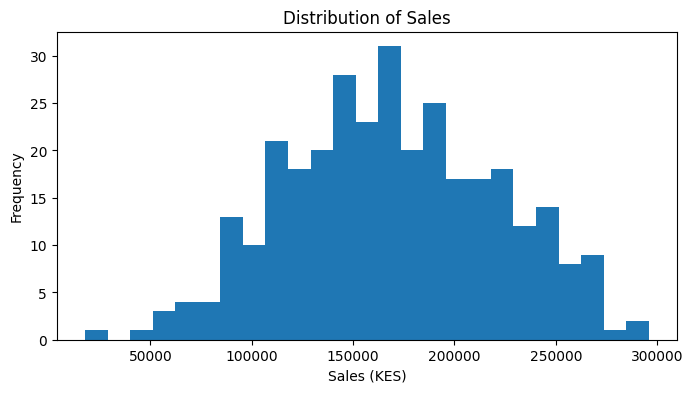

In [7]:
print("Missing values:")
display(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
display(df.describe(include="all"))
display(df["Sales_KES"].describe())

plt.figure(figsize=(8,4))
plt.hist(df["Sales_KES"], bins=25)
plt.title("Distribution of Sales")
plt.xlabel("Sales (KES)")
plt.ylabel("Frequency")
plt.show()

**Interpretation.** There are no missing values and no duplicate rows. Sales range from about KES 17,800 to KES 295,800 with a mean (≈169,300) almost equal to the median (≈168,500), and the histogram is roughly symmetric and bell-shaped (skewness ≈ 0.02). Only one record is flagged as an outlier by the 1.5×IQR rule (the very low end, ≈17,800). I have **not** removed it: a small-sales record is plausibly a genuine business case, and with only 320 rows there is no justification for dropping data without a business reason.

## Part 4 – Define the Analytical Task
- **Business question:** Can available business characteristics be used to estimate sales?
- **Analytical task:** supervised regression.
- **Target:** `Sales_KES`.
- **Features:** `AdvertisingSpend_KES`, `StoreVisits`, `DiscountPercent`, `Region`, `CustomerSegment`, `ProductCategory`.

## Part 5 – Separate Features and Target

In [8]:
X = df.drop(columns="Sales_KES")
y = df["Sales_KES"]
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (320, 6)
y shape: (320,)


## Part 6 – Train/Test Split
20% of the data is reserved as an untouched final test set. Model development and cross-validation use only the training set.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE
)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 256
Test rows: 64


## Part 7 – Identify Feature Types

In [10]:
numeric_features = [
    "AdvertisingSpend_KES",
    "StoreVisits",
    "DiscountPercent"
]
categorical_features = [
    "Region",
    "CustomerSegment",
    "ProductCategory"
]

## Part 8 – Leakage-Safe Preprocessing
Imputation, scaling and one-hot encoding are *learned* from data. Putting them inside a `Pipeline` means they are fitted only on the training portion each time, so no information from validation/test rows leaks in. (This dataset has no missing values, but the imputers keep the pipeline robust to future data that does.)

In [11]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

## Part 9 – Build Baselines
A baseline is the minimum reference: predict the training mean (or median) for every case.

In [12]:
mean_baseline = DummyRegressor(strategy="mean")
median_baseline = DummyRegressor(strategy="median")

mean_baseline.fit(X_train, y_train)
median_baseline.fit(X_train, y_train)

mean_pred = mean_baseline.predict(X_test)
median_pred = median_baseline.predict(X_test)

## Part 10 – Evaluation Metrics
- **MAE** – average absolute error in KES; lower is better.
- **RMSE** – like MAE but penalises large errors more; lower is better.
- **R²** – share of variation in sales explained; higher is better (0 ≈ no better than predicting the mean).

In [13]:
def evaluate_regression(y_true, y_pred, name):
    return pd.DataFrame({
        "Model": [name],
        "MAE": [mean_absolute_error(y_true, y_pred)],
        "RMSE": [np.sqrt(mean_squared_error(y_true, y_pred))],
        "R2": [r2_score(y_true, y_pred)]
    })

mean_results = evaluate_regression(y_test, mean_pred, "Mean Baseline")
median_results = evaluate_regression(y_test, median_pred, "Median Baseline")
pd.concat([mean_results, median_results], ignore_index=True)

,Model,MAE,RMSE,R2
0,Mean Baseline,39197.156982,48716.433918,-0.008396
1,Median Baseline,39146.750000,48649.470528,-0.005626


Both baselines have an R² of essentially 0 and an MAE of ≈ KES 39,000, which is what we expect from predicting a constant. The median baseline is marginally stronger (lower MAE and RMSE) but the two are practically tied.

## Part 11 – Linear Regression

In [14]:
linear_model = Pipeline([
    ("preprocess", preprocessor),
    ("model", LinearRegression())
])
linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)

linear_results = evaluate_regression(y_test, linear_pred, "Linear Regression")
linear_results

,Model,MAE,RMSE,R2
0,Linear Regression,13757.843478,17469.693466,0.870327


**Interpretation.** Yes on all counts: MAE falls from ≈ 39,100 to ≈ 13,800 (about a 65% reduction), RMSE falls from ≈ 48,600 to ≈ 17,500, and R² rises from ≈ 0 to ≈ 0.87. The model adds substantial predictive value over the baseline.

## Part 12 – Ridge Regression

In [15]:
ridge_model = Pipeline([
    ("preprocess", preprocessor),
    ("model", Ridge(alpha=1.0))
])
ridge_model.fit(X_train, y_train)
ridge_pred = ridge_model.predict(X_test)

ridge_results = evaluate_regression(y_test, ridge_pred, "Ridge Regression")
ridge_results

,Model,MAE,RMSE,R2
0,Ridge Regression,13714.400361,17458.820721,0.870488


Ridge (alpha = 1) is almost identical to ordinary Linear Regression (MAE differs by only ≈ KES 44). That is expected here: there are only a few predictors, they are barely correlated with each other, and the sample is not tiny relative to the number of features, so regularisation has little to correct.

## Part 13 – Shallow Decision Tree

In [16]:
tree_model = Pipeline([
    ("preprocess", preprocessor),
    ("model", DecisionTreeRegressor(
        max_depth=4,
        min_samples_leaf=8,
        random_state=RANDOM_STATE
    ))
])
tree_model.fit(X_train, y_train)
tree_pred = tree_model.predict(X_test)

tree_results = evaluate_regression(y_test, tree_pred, "Decision Tree")
tree_results

,Model,MAE,RMSE,R2
0,Decision Tree,23775.92494,28767.642109,0.648368


The shallow tree improves clearly on the baselines (R² ≈ 0.65) but is well behind the linear models. Sales appear to depend smoothly on `StoreVisits` and `AdvertisingSpend_KES`; a depth-4 tree can only approximate a smooth trend with a handful of flat steps.

## Part 14 – Compare All Models

In [17]:
comparison = pd.concat([
    mean_results,
    median_results,
    linear_results,
    ridge_results,
    tree_results
], ignore_index=True)
comparison.sort_values("MAE")

,Model,MAE,RMSE,R2
3,Ridge Regression,13714.400361,17458.820721,0.870488
2,Linear Regression,13757.843478,17469.693466,0.870327
4,Decision Tree,23775.924940,28767.642109,0.648368
1,Median Baseline,39146.750000,48649.470528,-0.005626
0,Mean Baseline,39197.156982,48716.433918,-0.008396


**Summary.** Ridge Regression has the lowest MAE (≈ 13,714), lowest RMSE (≈ 17,459) and highest R² (≈ 0.870), with Linear Regression a hair behind. From this table alone I would pick Ridge (or Linear Regression, since the difference is negligible and Linear is simpler to explain).

One table is still not enough: it comes from **a single 64-row test set**, so a different random split could shift the numbers, and the gap between Ridge and Linear (≈ 44 KES) is far smaller than that noise. It also says nothing about *where* the model fails (subgroups), whether errors show patterns, or whether the model is overfitting. Cross-validation, residual analysis and subgroup checks are needed before drawing a conclusion.

## Part 15 – Cross-Validation on Training Data Only

In [18]:
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}
models = {
    "Linear Regression": linear_model,
    "Ridge Regression": ridge_model,
    "Decision Tree": tree_model
}

rows = []
for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train,
        cv=5,
        scoring=scoring
    )
    rows.append({
        "Model": name,
        "CV_MAE": -scores["test_MAE"].mean(),
        "CV_RMSE": -scores["test_RMSE"].mean(),
        "CV_R2": scores["test_R2"].mean()
    })

cv_results = pd.DataFrame(rows)
cv_results

,Model,CV_MAE,CV_RMSE,CV_R2
0,Linear Regression,15976.774926,20126.771067,0.847517
1,Ridge Regression,15971.368173,20103.541323,0.847907
2,Decision Tree,24498.468304,30608.682961,0.650627


**Questions.**
- **Best on average:** Ridge (CV MAE ≈ 15,971, R² ≈ 0.848), with Linear Regression essentially tied (≈ 15,977). The tree is clearly worse (CV MAE ≈ 24,498).
- **Consistent with test results?** Yes in ranking and size of the gaps: linear models ≈ Ridge > tree >> baselines. The CV MAE (≈ 16,000) is a little worse than the test MAE (≈ 13,700); individual Linear Regression folds range from ≈ 13,400 to ≈ 18,200, so a 64-row test set landing at the lucky end of that range is unsurprising. If anything, the CV figure is the more conservative estimate of future error.
- **Why CV on training data is safer:** every time we look at test performance and use it to choose between models or settings, the test set quietly becomes part of model selection, and its score becomes optimistic. Cross-validating on the training data lets us compare and tune freely while the test set stays a one-time, honest final check.

## Part 16 – Residual Analysis
Residual = Actual − Predicted. Positive = under-predicted; negative = over-predicted.

,Actual,Predicted,Residual
0,149359,136532.314107,12826.685893
1,198924,196021.086894,2902.913106
2,152671,143638.944984,9032.055016
3,133621,172495.435274,-38874.435274
4,171171,149069.696640,22101.303360


Mean residual: -337.25
Std of residuals: 17604.51


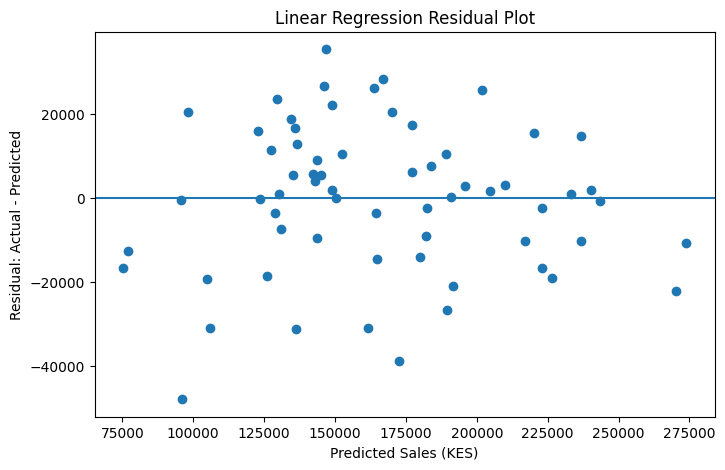

In [19]:
residuals = y_test - linear_pred
residual_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": linear_pred,
    "Residual": residuals.values
})
display(residual_df.head())
print("Mean residual:", round(residuals.mean(), 2))
print("Std of residuals:", round(residuals.std(), 2))

plt.figure(figsize=(8,5))
plt.scatter(linear_pred, residuals)
plt.axhline(0)
plt.title("Linear Regression Residual Plot")
plt.xlabel("Predicted Sales (KES)")
plt.ylabel("Residual: Actual - Predicted")
plt.show()

**Interpretation.** Residuals are centred close to zero (mean ≈ −337 KES against a standard deviation of ≈ 17,600), so the model is not systematically biased overall. There is no obvious curve or funnel in the plot, which supports a roughly linear relationship. Two things to note: (1) the few cases with the lowest predictions (below ≈ 110,000) are mostly over-predicted (negative residuals), and (2) a handful of large residuals exist (from about −48,000 to +35,000), the largest being an over-prediction.

## Part 17 – Actual vs Predicted

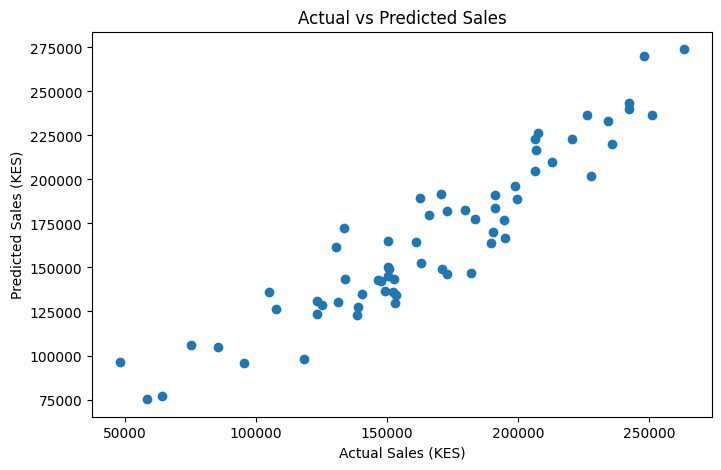

In [20]:
plt.figure(figsize=(8,5))
plt.scatter(y_test, linear_pred)
plt.title("Actual vs Predicted Sales")
plt.xlabel("Actual Sales (KES)")
plt.ylabel("Predicted Sales (KES)")
plt.show()

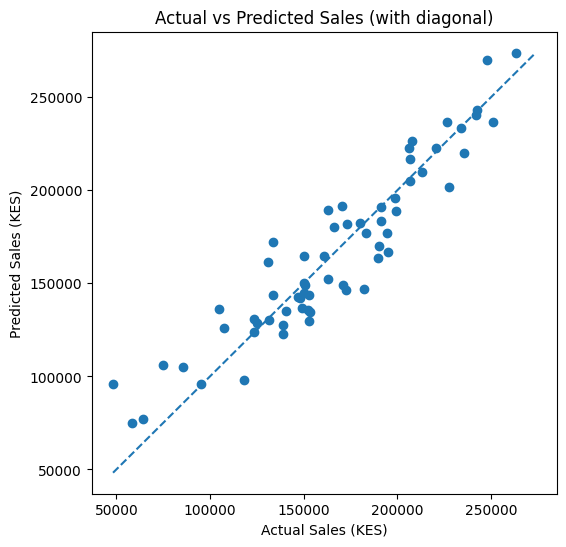

In [21]:
# Same plot with the Actual = Predicted reference line added
lims = [min(y_test.min(), linear_pred.min()), max(y_test.max(), linear_pred.max())]
plt.figure(figsize=(6,6))
plt.scatter(y_test, linear_pred)
plt.plot(lims, lims, linestyle="--")
plt.title("Actual vs Predicted Sales (with diagonal)")
plt.xlabel("Actual Sales (KES)")
plt.ylabel("Predicted Sales (KES)")
plt.show()

Points cluster reasonably tightly around the diagonal, consistent with R² ≈ 0.87. The scatter is wider at the low end of actual sales, where a few points sit clearly below the diagonal (over-predictions).

## Part 18 – Inspect Largest Errors

In [22]:
error_analysis = X_test.copy()
error_analysis["ActualSales"] = y_test
error_analysis["PredictedSales"] = linear_pred
error_analysis["Residual"] = (
    error_analysis["ActualSales"] - error_analysis["PredictedSales"]
)
error_analysis["AbsoluteError"] = error_analysis["Residual"].abs()

error_analysis.sort_values("AbsoluteError", ascending=False).head(10)

,AdvertisingSpend_KES,StoreVisits,DiscountPercent,Region,CustomerSegment,ProductCategory,ActualSales,PredictedSales,Residual,AbsoluteError
139,33386,161,22,Nairobi,Retail,Home,48229,96088.854657,-47859.854657,47859.854657
63,67888,265,4,Nakuru,SME,Accessories,133621,172495.435274,-38874.435274,38874.435274
46,33969,441,10,Nakuru,Retail,Accessories,182186,146807.115940,35378.884060,35378.884060
7,50328,108,13,Nairobi,Retail,Electronics,104994,136091.949761,-31097.949761,31097.949761
5,60808,257,8,Nairobi,Retail,Accessories,130757,161701.195990,-30944.195990,30944.195990
76,26462,114,13,Nairobi,Retail,Electronics,75103,106000.271668,-30897.271668,30897.271668
260,56576,151,0,Nairobi,Corporate,Home,195145,166919.218106,28225.781894,28225.781894
226,57562,410,21,Kisumu,Corporate,Office,162770,189424.021603,-26654.021603,26654.021603
73,13444,541,19,Nakuru,Retail,Electronics,172866,146216.703107,26649.296893,26649.296893
297,33529,285,3,Nairobi,Corporate,Office,189884,163816.773893,26067.226107,26067.226107


**Observations.**
- **Shared characteristics:** six of the ten largest errors have **low store visits** (roughly 108–265 visits, against a typical range of 84–848), and most of those are *over-predictions* (negative residuals). The single largest error is a Nairobi Retail/Home record with 161 visits and actual sales of only ≈ 48,000 against a prediction of ≈ 96,000.
- **Concentration:** Retail appears in six of the ten, and Nairobi in six, but Nairobi is also the largest region (about 43% of the data) and Retail the largest segment, so this is not strong evidence of a problem in either.
- **Possible extra data:** store size/location type, number of staff, local competition, stock availability/stock-outs, promotions or seasonal events, and customer type within a segment (e.g. one very large customer) could explain these records.

A quick extra check I ran when preparing this lab: when test records are split into terciles by `StoreVisits`, the low-visit tercile had an MAE of ≈ 20,000 versus ≈ 10,000–11,000 for the middle and high terciles. With only ≈ 21 rows per group this is suggestive rather than conclusive, but it points to the model being least reliable for low-traffic stores, which may reflect a non-linear effect at low traffic.

## Part 19 – Error by Customer Segment

In [23]:
segment_errors = error_analysis.groupby(
    "CustomerSegment"
).agg(
    Observations=("AbsoluteError", "size"),
    MAE=("AbsoluteError", "mean")
).reset_index()
segment_errors

,CustomerSegment,Observations,MAE
0,Corporate,19,14300.002844
1,Retail,27,15560.578163
2,SME,18,10481.462121


In [24]:
# Extra check: the same breakdown for Region and ProductCategory
for col in ["Region", "ProductCategory"]:
    display(
        error_analysis.groupby(col).agg(
            Observations=("AbsoluteError", "size"),
            MAE=("AbsoluteError", "mean")
        ).reset_index()
    )

,Region,Observations,MAE
0,Kisumu,12,11992.385359
1,Mombasa,11,12757.986862
2,Nairobi,28,13757.072552
3,Nakuru,13,16235.190104


,ProductCategory,Observations,MAE
0,Accessories,13,15928.884656
1,Electronics,16,13591.263067
2,Home,12,16880.345791
3,Office,23,11017.483631


**Explanation.** **Retail** has the highest MAE (≈ 15,561), followed by Corporate (≈ 14,300), while **SME** is lowest (≈ 10,481). Sample sizes are *not* similar (27 Retail vs 19 Corporate vs 18 SME in the test set), so with so few rows per group these MAEs are noisy and the differences should be treated as indicative only. Subgroup performance matters because an acceptable overall MAE can hide a group the model serves much worse; a model that is, say, 50% less accurate for Retail customers could lead to poor stock or budget decisions for the largest segment. The same pattern appears in the extra breakdowns: Nakuru (≈ 16,235) and the Home category (≈ 16,880) have the highest regional/category errors, again with only 12–13 test rows each.

## Part 20 – Check for Overfitting

In [25]:
tree_train_pred = tree_model.predict(X_train)
print("Shallow Tree Training MAE:", round(mean_absolute_error(y_train, tree_train_pred), 2))
print("Shallow Tree Test MAE:", round(mean_absolute_error(y_test, tree_pred), 2))

Shallow Tree Training MAE: 18029.7
Shallow Tree Test MAE: 23775.92


The shallow tree's training MAE (≈ 18,030) is lower than its test MAE (≈ 23,776), a gap of about 5,700 KES. Some gap is normal, and this one is moderate: the depth limit and `min_samples_leaf=8` are keeping the tree from memorising the training data.

## Part 21 – Demonstrate an Overly Deep Tree

In [26]:
deep_tree = Pipeline([
    ("preprocess", preprocessor),
    ("model", DecisionTreeRegressor(random_state=RANDOM_STATE))
])
deep_tree.fit(X_train, y_train)
deep_train_pred = deep_tree.predict(X_train)
deep_test_pred = deep_tree.predict(X_test)

print("Deep Tree Training MAE:", round(mean_absolute_error(y_train, deep_train_pred), 2))
print("Deep Tree Test MAE:", round(mean_absolute_error(y_test, deep_test_pred), 2))

Deep Tree Training MAE: 0.0
Deep Tree Test MAE: 26797.5


An unrestricted tree achieves a training MAE of **0** because it grows until every training row has its own leaf, i.e. it memorises the training data, including noise. Its test MAE (≈ 26,798) is *worse* than the shallow tree's (≈ 23,776). A near-perfect training score therefore says nothing about how a model handles new data; only held-out performance does.

## Part 22 – Extension Challenge
**Chosen option:** remove `AdvertisingSpend_KES` or `StoreVisits`, retrain Linear Regression and explain the performance change.

In [27]:
# Extension (option 3): drop AdvertisingSpend_KES or StoreVisits, retrain Linear Regression
def linear_without(drop_col):
    num = [c for c in numeric_features if c != drop_col]
    prep = ColumnTransformer([
        ("num", numeric_pipeline, num),
        ("cat", categorical_pipeline, categorical_features)
    ])
    m = Pipeline([("preprocess", prep), ("model", LinearRegression())])
    m.fit(X_train, y_train)
    return m.predict(X_test)

ext_results = pd.concat([
    linear_results.assign(Model="Linear (all features)"),
    evaluate_regression(y_test, linear_without("AdvertisingSpend_KES"), "Linear without AdvertisingSpend_KES"),
    evaluate_regression(y_test, linear_without("StoreVisits"), "Linear without StoreVisits"),
], ignore_index=True)
ext_results

,Model,MAE,RMSE,R2
0,Linear (all features),13757.843478,17469.693466,0.870327
1,Linear without AdvertisingSpend_KES,21432.037335,27065.724576,0.688743
2,Linear without StoreVisits,34428.077412,42291.400487,0.240051


In [28]:
# Bonus: which features carry the signal? (standardised numeric coefficients, KES per 1 SD)
names = linear_model.named_steps["preprocess"].get_feature_names_out()
coefs = pd.Series(linear_model.named_steps["model"].coef_, index=names).round(0)
coefs.sort_values(key=abs, ascending=False)

num__StoreVisits                    38757.0
num__AdvertisingSpend_KES           23323.0
cat__CustomerSegment_Corporate      14414.0
cat__ProductCategory_Electronics    12166.0
cat__CustomerSegment_Retail        -10148.0
cat__ProductCategory_Home           -7315.0
cat__Region_Nairobi                  6976.0
num__DiscountPercent                -6211.0
cat__Region_Kisumu                  -4969.0
cat__ProductCategory_Accessories    -4632.0
cat__CustomerSegment_SME            -4266.0
cat__Region_Nakuru                  -1885.0
cat__ProductCategory_Office          -220.0
cat__Region_Mombasa                  -123.0
dtype: float64

**Explanation.** Removing `AdvertisingSpend_KES` raises the MAE from ≈ 13,758 to ≈ 21,432 (R² 0.87 → 0.69). Removing `StoreVisits` is far more damaging: MAE rises to ≈ 34,428 and R² collapses to ≈ 0.24, almost back to baseline level. So `StoreVisits` is the single most informative predictor and advertising spend is the second. This matches the standardised coefficients (≈ +38,800 KES per standard deviation of visits versus ≈ +23,300 for advertising) and the correlations in the raw data (0.77 and 0.48 with sales). `DiscountPercent` has a small *negative* coefficient. These are associations in the data, not proof of cause and effect.

## Part 23 – Final Recommendation
The strongest baseline was the **median baseline** (MAE ≈ 39,147), though it was practically tied with the mean baseline and both have R² ≈ 0. The best candidate was **Ridge Regression** (test MAE ≈ 13,714, RMSE ≈ 17,459, R² ≈ 0.87; CV MAE ≈ 15,971), only marginally ahead of plain Linear Regression, and it clearly beat the baseline by cutting MAE by roughly 65%. In business terms, a typical prediction is off by about KES 14,000–16,000, around 8–9% of average sales; about 73% of test predictions were within KES 20,000 of the actual value and 41% within KES 10,000. Residual analysis showed no overall bias and no strong pattern, but the largest errors were mostly over-predictions for low-store-visit records. Performance differed by segment (Retail MAE ≈ 15,600 vs SME ≈ 10,500), although the subgroup samples are small. The shallow tree showed a moderate train/test gap and the unrestricted tree showed clear overfitting (training MAE 0 vs test MAE ≈ 26,800), whereas the linear models did not appear to overfit. I would **not deploy immediately**: I would first confirm the results on newer data, investigate the weaker low-traffic cases, and agree with the business whether an error of about KES 15,000 is acceptable for the decisions it would support. It is a sound candidate for a pilot or decision-support tool.

## Part 24 – Limitations
1. **Small dataset:** 320 rows, and a test set of only 64, so metrics (especially subgroup MAEs with 12–27 rows each) are noisy.
2. **Teaching/synthetic-looking data:** clean data with no missing values or duplicates and a very tidy relationship suggest this is not real-world transaction data, so performance may not transfer.
3. **Limited predictors / missing external factors:** no time, seasonality, store size, competitor activity, stock levels or macro-economic variables, which likely explain the largest errors.
4. **Data drift:** a model trained on past data may degrade if customer behaviour, pricing or market conditions change.
5. **Prediction is not causation:** the strong link between store visits/advertising and sales does not prove that increasing them will cause sales to rise by the same amount.
6. **Single split and fixed settings:** one random 80/20 split and untuned hyperparameters (Ridge alpha = 1, tree depth 4); repeated CV or tuning could change the ranking among close models.